<a href="https://colab.research.google.com/github/asma-benali-dz/Machine-learning-course/blob/master/regression_lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")


def evaluate(y_true, y_pred):
    """Return MAE, MSE, RMSE and R2 for one set of predictions."""
    mse = mean_squared_error(y_true, y_pred)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_true, y_pred),
    }

## Task 1. Generate the dataset

Steps: fix the random seed, draw the experience values, **then** draw the noise, then apply the formula.

The order matters. NumPy's random generator is a single stream of numbers: whatever is drawn first gets the first numbers. Drawing experience before noise is what makes the result identical to the reference solution.

- `slope = (200000 - 60000) / (18 - 0)` = about 7,777.78 per extra year, so that 0 years maps to 60,000 and 18 years to 200,000 (before noise).
- No CSV file is read: the data is generated in memory.

In [ ]:
np.random.seed(42)

n_samples = 500
years = np.random.randint(0, 19, size=n_samples)       # integers 0..18 inclusive (upper bound 19 is excluded)

intercept = 60000
slope = (200000 - 60000) / (20 - 2)                    # about 7777.78 per year

noise = np.random.normal(0, 10000, size=n_samples)     # mean 0, standard deviation 10,000

salary = intercept + slope * years + noise

df = pd.DataFrame({"YearsOfExperience": years, "Salary": salary})

print("First five rows:")
display(df.head())
print("Shape:", df.shape)
assert df.shape == (500, 2), "unexpected shape"
print(f"True slope = {slope:.2f}, true intercept = {intercept}")

First five rows:


,YearsOfExperience,Salary
0,6,"99,482.22"
1,14,"166,754.42"
2,10,"140,886.85"
3,7,"129,198.01"
4,6,"115,243.26"


Shape: (500, 2)
True slope = 7777.78, true intercept = 60000


## Task 2. Explore the dataset

We look at the size, summary statistics (count, mean, std, min, quartiles, max), missing values, and the Pearson correlation between experience and salary (+1 = perfect straight-line increase, 0 = no linear relation).

In [ ]:
print("Shape:", df.shape)

print("\nSummary statistics:")
display(df.describe())

print("Missing values per column:")
display(df.isna().sum().to_frame("missing"))

correlation = df["YearsOfExperience"].corr(df["Salary"])
print(f"Correlation between YearsOfExperience and Salary: {correlation:.4f}")

Shape: (500, 2)

Summary statistics:


,YearsOfExperience,Salary
count,500.00,500.00
mean,8.62,"127,014.46"
std,5.66,"44,935.26"
min,0.00,"39,325.58"
25%,3.75,"88,870.75"
50%,8.00,"124,309.48"
75%,14.00,"166,785.57"
max,18.00,"226,323.82"


Missing values per column:


,missing
YearsOfExperience,0
Salary,0


Correlation between YearsOfExperience and Salary: 0.9751


## Task 3. Plot the data

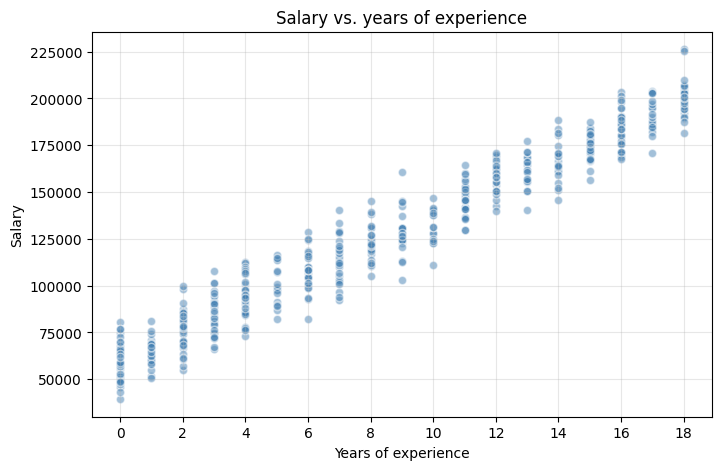

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(df["YearsOfExperience"], df["Salary"], alpha=0.5, edgecolor="white", color="steelblue")
plt.xlabel("Years of experience")
plt.ylabel("Salary")
plt.title("Salary vs. years of experience")
plt.xticks(range(0, 19, 2))

plt.grid(alpha=0.3)
plt.savefig("salary_plot.png", dpi=150)
plt.show()

## Task 4. Split the dataset

- `X` must be **2-dimensional** (rows x features), which is why we write `df[["YearsOfExperience"]]` (double brackets) and not `df["YearsOfExperience"]`.
- `y` is a 1-D column of targets.
- 80% of the rows train the model, the remaining 20% are kept hidden and used only for evaluation. `random_state=42` makes the shuffle reproducible.

In [ ]:
X = df[["YearsOfExperience"]]     # 2-D: DataFrame with one column
y = df["Salary"]                  # 1-D: Series

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"X_train: {X_train.shape}   y_train: {y_train.shape}")
print(f"X_test : {X_test.shape}   y_test : {y_test.shape}")
print(f"Training set: {len(X_train)} rows ({len(X_train) / len(df):.0%}), test set: {len(X_test)} rows ({len(X_test) / len(df):.0%})")

X_train: (400, 1)   y_train: (400,)
X_test : (100, 1)   y_test : (100,)
Training set: 400 rows (80%), test set: 100 rows (20%)


## Task 5. Train linear regression

`LinearRegression` finds the line `Salary = intercept + slope * Years` that minimises the squared error on the training data.
`slope` is stored in `coef_`, `intercept` in `intercept_`.

R2 is shown for both sets. If training R2 were much higher than test R2, the model would be overfitting; here we expect them to be close.

هذي تاع تدريب المودل  تاعي

In [ ]:
lin_reg_model = LinearRegression()
lin_reg_model.fit(X_train, y_train)

lin_slope = lin_reg_model.coef_[0]
lin_intercept = lin_reg_model.intercept_

print(f"Slope      : {lin_slope:,.2f}   (true value: {slope:,.2f})")
print(f"Intercept  : {lin_intercept:,.2f}   (true value: {intercept:,.2f})")
print(f"Training R2: {lin_reg_model.score(X_train, y_train):.4f}")
print(f"Test R2    : {lin_reg_model.score(X_test, y_test):.4f}")

Slope      : 7,696.61   (true value: 7,777.78)
Intercept  : 60,799.01   (true value: 60,000.00)
Training R2: 0.9488
Test R2    : 0.9574


In [ ]:
slope


7777.777777777777

## Task 6. Evaluate linear regression on the test set

In [ ]:
print(X_test["YearsOfExperience"].values[10])
print(y_test.values[10])
print(lin_reg_model.predict([[X_test["YearsOfExperience"].values[10]]])[0])

7
111557.85805524305
114675.30163219337


c:\Users\Home\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [ ]:
y_pred_lin = lin_reg_model.predict(X_test)
lin_metrics = evaluate(y_test, y_pred_lin)

for name, value in lin_metrics.items():
    print(f"{name:<5}: {value:,.4f}" if name == "R2" else f"{name:<5}: {value:,.2f}")

print("\nFive actual vs. predicted pairs (first five test rows):")
pairs = pd.DataFrame({
    "YearsOfExperience": X_test["YearsOfExperience"].values[:5],
    "Actual": y_test.values[:5],
    "Predicted": y_pred_lin[:5],
})
pairs["Error (actual - predicted)"] = pairs["Actual"] - pairs["Predicted"]
display(pairs)

MAE  : 7,905.11
MSE  : 93,933,277.38
RMSE : 9,691.92
R2   : 0.9574

Five actual vs. predicted pairs (first five test rows):


,YearsOfExperience,Actual,Predicted,Error (actual - predicted)
0,4,"108,075.67","91,585.46","16,490.21"
1,6,"124,220.08","106,978.69","17,241.39"
2,4,"77,629.26","91,585.46","-13,956.21"
3,11,"151,185.25","145,461.75","5,723.49"
4,14,"159,031.63","168,551.59","-9,519.96"


In [ ]:
linear_predicted = lin_reg_model.predict(X_test)
print("MAE:", mean_absolute_error(y_test, linear_predicted))
print("MSE:", mean_squared_error(y_test, linear_predicted))
print("RMSE:", np.sqrt(mean_squared_error(y_test, linear_predicted)))
print("R2:", r2_score(y_test, linear_predicted))

MAE: 7905.114728709231
MSE: 93933277.37947087
RMSE: 9691.918147584145
R2: 0.9573704756930143


In [ ]:
linear_predicted

array([ 91585.46286304, 106978.68870914,  91585.46286304, 145461.7533244 ,
       168551.59209356,  91585.46286304, 130068.5274783 , 137765.14040135,
       153158.36624745, 145461.7533244 , 114675.30163219,  60799.01117083,
        68495.62409388,  60799.01117083,  60799.01117083, 191641.43086271,
       183944.81793966, 106978.68870914, 183944.81793966, 191641.43086271,
       199338.04378577, 114675.30163219,  76192.23701693, 145461.7533244 ,
       145461.7533244 , 176248.20501661, 153158.36624745, 145461.7533244 ,
        60799.01117083, 176248.20501661, 130068.5274783 , 191641.43086271,
       183944.81793966,  83888.84993999, 137765.14040135, 114675.30163219,
        76192.23701693, 168551.59209356,  60799.01117083, 114675.30163219,
       176248.20501661,  68495.62409388, 191641.43086271,  99282.07578609,
       160854.97917051, 114675.30163219, 106978.68870914,  68495.62409388,
       122371.91455525, 168551.59209356,  60799.01117083, 176248.20501661,
       153158.36624745, 1

In [ ]:
y_test

361   108,075.67
73    124,220.08
374    77,629.26
155   151,185.25
104   159,031.63
         ...    
347    64,682.31
86    145,023.57
75     69,715.71
438    83,894.78
15     64,017.12
Name: Salary, Length: 100, dtype: float64

## Task 7. Compare with a baseline

A **baseline** is the dumbest reasonable model. Here: ignore experience and always predict the *training-set* average salary. Any useful model must beat it. (We use the training mean, never the test mean, to avoid leaking test information.)

In [ ]:
baseline_value = y_train.mean()
y_pred_base = np.full(len(y_test), baseline_value)
base_metrics = evaluate(y_test, y_pred_base)

print(f"Baseline prediction for every record: {baseline_value:,.2f}")

comparison_7 = pd.DataFrame({
    "Mean baseline": [base_metrics["MAE"], base_metrics["RMSE"]],
    "Linear regression": [lin_metrics["MAE"], lin_metrics["RMSE"]],
}, index=["Test MAE", "Test RMSE"])
comparison_7["Improvement"] = 1 - comparison_7["Linear regression"] / comparison_7["Mean baseline"]
display(comparison_7.style.format({"Mean baseline": "{:,.2f}", "Linear regression": "{:,.2f}", "Improvement": "{:.1%}"}))

Baseline prediction for every record: 126,797.47


,Mean baseline,Linear regression,Improvement
Test MAE,"40,444.96","7,905.11",80.5%
Test RMSE,"46,953.77","9,691.92",79.4%


## Task 8. Plot predictions and residuals

- **(a)** test points with the fitted line: the line should run through the middle of the cloud.
- **(b)** residuals = actual - predicted. For a good linear fit they should scatter randomly around the zero line, with no curve or funnel shape (a pattern would mean the model is missing something).

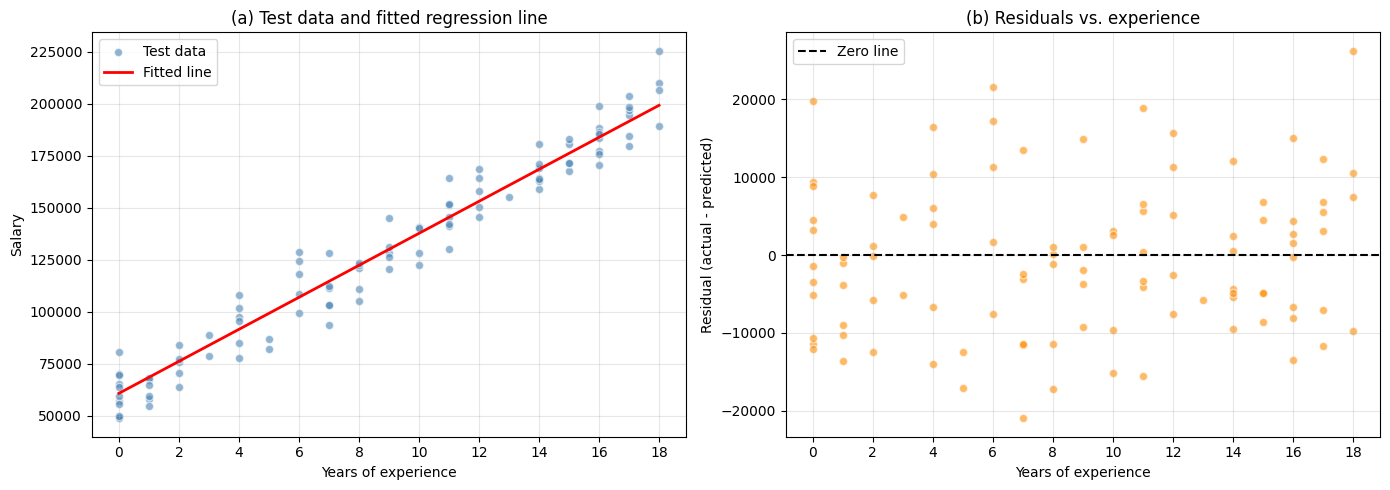

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) test data + fitted regression line
line_x = pd.DataFrame({"YearsOfExperience": np.linspace(0, 18, 100)})
axes[0].scatter(X_test["YearsOfExperience"], y_test, alpha=0.6, color="steelblue", edgecolor="white", label="Test data")
axes[0].plot(line_x["YearsOfExperience"], lin_reg.predict(line_x), color="red", linewidth=2, label="Fitted line")
axes[0].set_xlabel("Years of experience")
axes[0].set_ylabel("Salary")
axes[0].set_title("(a) Test data and fitted regression line")
axes[0].set_xticks(range(0, 19, 2))
axes[0].legend()
axes[0].grid(alpha=0.3)

# (b) residuals vs experience
residuals = y_test - y_pred_lin
axes[1].scatter(X_test["YearsOfExperience"], residuals, alpha=0.6, color="darkorange", edgecolor="white")
axes[1].axhline(0, color="black", linestyle="--", linewidth=1.5, label="Zero line")
axes[1].set_xlabel("Years of experience")
axes[1].set_ylabel("Residual (actual - predicted)")
axes[1].set_title("(b) Residuals vs. experience")
axes[1].set_xticks(range(0, 19, 2))
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Task 9. Predict new salaries

In [ ]:
new_years = pd.DataFrame({"YearsOfExperience": [5, 10, 15]})   # same column name as in training
new_pred = lin_reg.predict(new_years)

predictions_table = new_years.assign(PredictedSalary=new_pred)
display(predictions_table.style.format({"PredictedSalary": "{:,.2f}"}).hide(axis="index"))

YearsOfExperience,PredictedSalary
5,"99,282.08"
10,"137,765.14"
15,"176,248.21"


## Task 10. Standardize the feature

Ridge and Lasso add a penalty on the size of the coefficients, so the feature must be on a sensible scale. `StandardScaler` converts each value to `(x - mean) / std`.

**Important rule: fit the scaler on the training data only**, then reuse the same mean/std to transform the test data. Fitting on the test set (or on all data) would leak test information into training. The target `y` is not scaled, so predictions stay in real salary units.

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # learns mean/std from X_train, then transforms it
X_test_scaled = scaler.transform(X_test)         # only transforms, using the training mean/std

print(f"Training mean used by the scaler: {scaler.mean_[0]:.4f}")
print(f"Training std used by the scaler : {scaler.scale_[0]:.4f}")
print(f"Scaled X_train -> mean {X_train_scaled.mean():.4f}, std {X_train_scaled.std():.4f}   (exactly 0 and 1)")
print(f"Scaled X_test  -> mean {X_test_scaled.mean():.4f}, std {X_test_scaled.std():.4f}   (close to, not exactly, 0 and 1: expected)")

Training mean used by the scaler: 8.5750
Training std used by the scaler : 5.6142
Scaled X_train -> mean 0.0000, std 1.0000   (exactly 0 and 1)
Scaled X_test  -> mean 0.0365, std 1.0373   (close to, not exactly, 0 and 1: expected)


## Task 11. Train Ridge regression

Ridge = linear regression + an **L2 penalty** (`alpha * coefficient^2`) that shrinks the coefficient. Larger `alpha` means stronger shrinkage.

Because the feature is standardized, the coefficient is the salary change per **one standard deviation** of experience (not per year). The column *Equivalent slope per year* converts it back (`coef / std`) so it can be compared with the linear-regression slope.

In [ ]:
ridge_rows = []
ridge_models = {}

for alpha in [10, 100]:
    model = Ridge(alpha=alpha)
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)
    ridge_models[alpha] = model
    ridge_rows.append({
        "alpha": alpha,
        "Coefficient (per 1 std)": model.coef_[0],
        "Equivalent slope per year": model.coef_[0] / scaler.scale_[0],
        "Test MAE": mean_absolute_error(y_test, pred),
        "Test R2": r2_score(y_test, pred),
    })

ridge_table = pd.DataFrame(ridge_rows).set_index("alpha")
display(ridge_table.style.format({"Coefficient (per 1 std)": "{:,.2f}", "Equivalent slope per year": "{:,.2f}",
                                  "Test MAE": "{:,.2f}", "Test R2": "{:.4f}"}))

ridge_final = ridge_models[10]     # retained for the final comparison (Task 13)
y_pred_ridge = ridge_final.predict(X_test_scaled)

,Coefficient (per 1 std),Equivalent slope per year,Test MAE,Test R2
alpha,,,,
10,"42,156.50","7,508.89","8,084.46",0.9557
100,"34,568.33","6,157.29","11,308.37",0.9118


## Task 12. Train Lasso regression

Lasso = linear regression + an **L1 penalty** (`alpha * |coefficient|`). Unlike Ridge, L1 can shrink a coefficient all the way to **exactly zero** (it "switches the feature off"). When that happens the model predicts a constant, i.e. the mean salary.

`max_iter=20000` gives the optimiser enough iterations to converge. `alpha` values are large because salaries are in the tens of thousands.

In [ ]:
lasso_rows = []
lasso_models = {}

for alpha in [1000, 10000, 50000]:
    model = Lasso(alpha=alpha, max_iter=20000)
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)
    lasso_models[alpha] = model
    lasso_rows.append({
        "alpha": alpha,
        "Coefficient (per 1 std)": model.coef_[0],
        "Equivalent slope per year": model.coef_[0] / scaler.scale_[0],
        "Test MAE": mean_absolute_error(y_test, pred),
        "Test R2": r2_score(y_test, pred),
    })

lasso_table = pd.DataFrame(lasso_rows).set_index("alpha")
display(lasso_table.style.format({"Coefficient (per 1 std)": "{:,.2f}", "Equivalent slope per year": "{:,.2f}",
                                  "Test MAE": "{:,.2f}", "Test R2": "{:.4f}"}))

lasso_final = lasso_models[1000]   # retained for the final comparison (Task 13)
y_pred_lasso = lasso_final.predict(X_test_scaled)

,Coefficient (per 1 std),Equivalent slope per year,Test MAE,Test R2
alpha,,,,
1000,"42,210.42","7,518.49","8,074.65",0.9558
10000,"33,210.42","5,915.42","12,287.96",0.8980
50000,0.00,0.00,"40,444.96",-0.0005


## Task 13. Compare the models

All four models are evaluated on the same test set.

In [ ]:
final_table = pd.DataFrame(
    {
        "Mean baseline": base_metrics,
        "Linear regression": lin_metrics,
        "Ridge (alpha=10)": evaluate(y_test, y_pred_ridge),
        "Lasso (alpha=1000)": evaluate(y_test, y_pred_lasso),
    }
).T[["MAE", "RMSE", "R2"]]
final_table.columns = ["Test MAE", "Test RMSE", "Test R2"]

display(final_table.style.format({"Test MAE": "{:,.2f}", "Test RMSE": "{:,.2f}", "Test R2": "{:.4f}"}))

,Test MAE,Test RMSE,Test R2
Mean baseline,"40,444.96","46,953.77",-0.0005
Linear regression,"7,905.11","9,691.92",0.9574
Ridge (alpha=10),"8,084.46","9,876.93",0.9557
Lasso (alpha=1000),"8,074.65","9,864.61",0.9558


### Conclusion

_(to be written after the first run)_

---
## Extra: automatic self-checks

These assertions are not part of the assignment. They re-verify the key results with independent methods, so a reader can trust the numbers above. If any check fails, the cell raises an error.

In [ ]:
# 1. data shape and quality
assert df.shape == (500, 2) and df.isna().sum().sum() == 0
assert df["YearsOfExperience"].between(0, 18).all() and df["YearsOfExperience"].dtype.kind == "i"

# 2. split sizes
assert (len(X_train), len(X_test)) == (400, 100)

# 3. no data leakage: the scaler statistics must equal the TRAINING statistics
assert np.isclose(scaler.mean_[0], X_train["YearsOfExperience"].mean())
assert np.isclose(scaler.scale_[0], X_train["YearsOfExperience"].std(ddof=0))

# 4. independent cross-check of linear regression with np.polyfit (least squares)
poly_slope, poly_intercept = np.polyfit(X_train["YearsOfExperience"], y_train, deg=1)
assert np.isclose(lin_slope, poly_slope) and np.isclose(lin_intercept, poly_intercept)

# 5. the model recovers the true generating rule (within sampling error)
assert abs(lin_slope - slope) < 400, "slope far from the true value"
assert abs(lin_intercept - intercept) < 5000, "intercept far from the true value"

# 6. RMSE really is sqrt(MSE), and the linear model beats the baseline
assert np.isclose(lin_metrics["RMSE"], np.sqrt(lin_metrics["MSE"]))
assert lin_metrics["MAE"] < base_metrics["MAE"] and lin_metrics["R2"] > base_metrics["R2"]

# 7. Ridge and Lasso against their exact closed-form solutions (single standardized feature, centred target)
xs = X_train_scaled[:, 0]
yc = y_train.values - y_train.mean()
ols_scaled = (xs * yc).sum() / (xs ** 2).sum()          # OLS coefficient on the scaled feature
for a in [10, 100]:                                      # Ridge: sum(xs*yc) / (sum(xs^2) + alpha)
    expected = (xs * yc).sum() / ((xs ** 2).sum() + a)
    assert np.isclose(ridge_models[a].coef_[0], expected), f"Ridge alpha={a} mismatch"
for a in [1000, 10000, 50000]:                           # Lasso: soft-thresholding of the OLS coefficient by alpha
    expected = np.sign(ols_scaled) * max(abs(ols_scaled) - a, 0.0)
    assert np.isclose(lasso_models[a].coef_[0], expected, atol=1e-3), f"Lasso alpha={a} mismatch"

# 8. Lasso with a huge alpha switches the feature off (coefficient exactly 0)
assert lasso_models[50000].coef_[0] == 0.0

print("All self-checks passed.")

All self-checks passed.
